# Mini Project Final — Lokalet e Prishtinës

**Python për Data Science — Module 6**

Në këtë projekt do të bashkojmë gjithçka mësuam në sesionet 1–5:

- **Sesioni 1:** Python bazë (variabla, listat, sintaksa)
- **Sesionet 2–3:** Pandas (DataFrame, filtrim, pastrim, groupby)
- **Sesioni 4:** Kolona të reja, logjikë, apply
- **Sesioni 5:** Vizualizim (Matplotlib + Seaborn)

##  Dataseti: `lokalet_prishtine.csv`

> **Shënim:** Emrat e lokaleve dhe të gjitha vlerat (çmimet, rating-u, komentet) janë **fiktive**, të krijuara vetëm për mësim.

**45 lokale** (kafene, restorante, bare, pizzeri) nga **8 lagjet kryesore** të Prishtinës: 
Qendër, Pejton, Dardania, Ulpiana, Kalabria, Aktash, Bregu i Diellit, Lakrishte.

| Kolona | Përshkrimi |
|---|---|
| `ID` | Identifikuesi i lokalit (p.sh. L001) |
| `Emri` | Emri i lokalit |
| `Lagjja` | Lagjja ku ndodhet (Qendër, Pejton, Dardania...) |
| `Tipi` | Kafe · Restorant · Bar · Pizzeri |
| `Cmimi_Mesatar` | Çmimi mesatar i konsumimit (**€**) |
| `Rating` | Vlerësimi 1–5 yje |
| `Nr_Komente` | Numri i komenteve nga klientët |
| `Viti_Hapjes` | Viti kur është hapur |
| `Nr_Tavolinave` | Sa tavolina ka brenda |
| `WiFi` | Po / Jo |

##  Pyetjet që do t'i përgjigjemi

1. **Cila lagje ka rating-un mesatar më të lartë?**
2. **Si ndryshojnë çmimet sipas tipit të lokalit?**
3. **A lidhet çmimi me rating-un?**
4. **Cila është "vlera për para" më e mirë në Prishtinë?**

---
##  Hapi 0 — Setup

Importojmë librarite që do na duhen.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

---
##  Hapi 1 — Njohja me të Dhënat

Lexojmë CSV-në dhe shohim çfarë kemi përballë.

In [2]:
df = pd.read_csv('../data/lokalet_prishtine.csv')
# df

In [3]:
# Sa rreshta dhe kolona kemi?
print(f'Forma e datasetit: {df.shape[0]} rreshta × {df.shape[1]} kolona')
print()
df.info()

Forma e datasetit: 45 rreshta × 10 kolona

<class 'pandas.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             45 non-null     str    
 1   Emri           45 non-null     str    
 2   Lagjja         44 non-null     str    
 3   Tipi           45 non-null     str    
 4   Cmimi_Mesatar  45 non-null     str    
 5   Rating         42 non-null     float64
 6   Nr_Komente     43 non-null     float64
 7   Viti_Hapjes    45 non-null     int64  
 8   Nr_Tavolinave  45 non-null     int64  
 9   WiFi           45 non-null     str    
dtypes: float64(2), int64(2), str(6)
memory usage: 3.6 KB


In [4]:
# Statistika bazë për kolonat numerike
df.describe()

,Rating,Nr_Komente,Viti_Hapjes,Nr_Tavolinave
count,42.000000,43.000000,45.000000,45.000000
mean,4.076190,188.046512,2014.555556,14.000000
std,0.350477,110.838998,3.957476,4.636809
min,3.400000,45.000000,2005.000000,6.000000
25%,3.800000,97.000000,2012.000000,10.000000
50%,4.000000,158.000000,2015.000000,14.000000
75%,4.400000,250.500000,2018.000000,18.000000
max,4.700000,538.000000,2020.000000,25.000000


In [5]:
df.Cmimi_Mesatar.unique()

<StringArray>
[   '3.5',    '3.0',    '3.2',    '2.8',    '2.5',    '2.7',    '2.2',
    '2.0',    '2.4',    '1.8',    '1.5',    '6.5',    '7 €',    '6.0',
    '5.5',    '4.5',    '4.0',    '8.5',    '5.0',   '18.0',   '22.0',
   '25.0', '12.00€',   '10.0',    '9.0',   '15.0',    '7.5',    '8.0',
   '20.0',   '16.0',    '2.6']
Length: 31, dtype: str

###  Çfarë vërejmë?

- `Cmimi_Mesatar` është **object** (jo numerik!) — disa vlera kanë simbolin **€** brenda.
- `Rating` dhe `Nr_Komente` kanë më pak se 45 vlera — ka **NaN**.
- Mund të ketë duplikate (kontrollojmë më pas).

---
##  Hapi 2 — Pastrimi i të Dhënave

### 2.1 Kontrollimi i NaN dhe duplikateve

In [6]:
# Sa vlera mungojnë në secilën kolonë?
df.isna().sum()

ID               0
Emri             0
Lagjja           1
Tipi             0
Cmimi_Mesatar    0
Rating           3
Nr_Komente       2
Viti_Hapjes      0
Nr_Tavolinave    0
WiFi             0
dtype: int64

In [7]:
# Sa duplikate ka?
print(f'Numri i duplikateve: {df.duplicated().sum()}')
df[df.duplicated(keep=False)].sort_values('ID')

Numri i duplikateve: 2


,ID,Emri,Lagjja,Tipi,Cmimi_Mesatar,Rating,Nr_Komente,Viti_Hapjes,Nr_Tavolinave,WiFi
6,L007,Kafe Kurora,Pejton,Kafe,3.0,4.4,220.0,2017,18,Po
43,L007,Kafe Kurora,Pejton,Kafe,3.0,4.4,220.0,2017,18,Po
22,L023,Pizzeri Roma e Vogël,Dardania,Pizzeri,5.0,3.9,142.0,2018,18,Po
44,L023,Pizzeri Roma e Vogël,Dardania,Pizzeri,5.0,3.9,142.0,2018,18,Po


### 2.2 Heqim duplikatet

In [8]:
df = df.drop_duplicates().reset_index(drop=True)
print(f'Pas heqjes së duplikateve: {df.shape[0]} rreshta')

Pas heqjes së duplikateve: 43 rreshta


### 2.3 Pastrojmë kolonën `Cmimi_Mesatar`

Disa vlera kanë **"€"** brenda (p.sh. `"7 €"`, `"12.00€"`). E pastrojmë.

In [9]:
# Shohim cilat vlera janë problematike
df[df['Cmimi_Mesatar'].astype(str).str.contains('€', na=False)]

,ID,Emri,Lagjja,Tipi,Cmimi_Mesatar,Rating,Nr_Komente,Viti_Hapjes,Nr_Tavolinave,WiFi
14,L015,Bar Nota,Qendër,Bar,7 €,4.5,318.0,2011,20,Po
29,L030,Te Fqinji,Bregu i Diellit,Restorant,12.00€,4.2,188.0,2015,20,Po


In [10]:
# Heqim simbolin '€' dhe boshllëqet, pastaj e kthejmë në numerik
df['Cmimi_Mesatar'] = (
    df['Cmimi_Mesatar']
    .astype(str)
    .str.replace('€', '', regex=False)
    .str.strip()
)
df['Cmimi_Mesatar'] = pd.to_numeric(df['Cmimi_Mesatar'], errors='coerce')

print('Tipi i ri:', df['Cmimi_Mesatar'].dtype)
df['Cmimi_Mesatar'].describe()

Tipi i ri: float64


count    43.000000
mean      6.720930
std       5.845452
min       1.500000
25%       2.750000
50%       4.500000
75%       8.250000
max      25.000000
Name: Cmimi_Mesatar, dtype: float64

### 2.4 Trajtimi i vlerave NaN

**Strategjia:**
- `Lagjja` mungon → e heqim atë rresht (s'mund të analizojmë pa lagje).
- `Rating` mungon → e mbushim me **mesataren e tipit** të lokalit.
- `Nr_Komente` mungon → e mbushim me **0** (s'ka komente).

In [11]:
# 1. Heqim rreshtat ku mungon Lagjja
df = df.dropna(subset=['Lagjja']).reset_index(drop=True)

# 2. Rating → mesatarja e tipit
df['Rating'] = df.groupby('Tipi')['Rating'].transform(lambda x: x.fillna(x.mean()))
df['Rating'] = df['Rating'].round(2)

# 3. Nr_Komente → 0
df['Nr_Komente'] = df['Nr_Komente'].fillna(0).astype(int)

# Kontrolli final
print('NaN të mbetur:')
print(df.isna().sum())

NaN të mbetur:
ID               0
Emri             0
Lagjja           0
Tipi             0
Cmimi_Mesatar    0
Rating           0
Nr_Komente       0
Viti_Hapjes      0
Nr_Tavolinave    0
WiFi             0
dtype: int64


 **Dataset i pastruar!** Tani është gati për analizë.

---
##  Hapi 3 — Krijimi i Kolonave të Reja

Tani krijojmë **kolona të reja** që na japin më shumë vlerë analitike.

In [12]:
# 3.1 Sa vjeçar është lokali?
df['Mosha'] = 2026 - df['Viti_Hapjes']

# 3.2 Kategori çmimi (kategori e re bazuar në logjikë)
def kategori_cmimi(c):
    if c < 4:
        return 'Lirë'
    elif c < 10:
        return 'Mesatar'
    else:
        return 'Shtrenjtë'

df['Kategoria_Cmimit'] = df['Cmimi_Mesatar'].apply(kategori_cmimi)

# 3.3 Vlera për para — rating për 1 € të shpenzuar
df['Value_Score'] = (df['Rating'] / df['Cmimi_Mesatar']).round(2)

# 3.4 A është popullor? (më shumë se 200 komente)
df['Popullor'] = np.where(df['Nr_Komente'] > 200, 'Po', 'Jo')

df[['Emri', 'Lagjja', 'Tipi', 'Cmimi_Mesatar', 'Rating', 'Mosha', 'Kategoria_Cmimit', 'Value_Score', 'Popullor']].head(10)

,Emri,Lagjja,Tipi,Cmimi_Mesatar,Rating,Mosha,Kategoria_Cmimit,Value_Score,Popullor
0,Kafe Libri,Pejton,Kafe,3.5,4.70,17,Lirë,1.34,Po
1,Kafe Hëna,Qendër,Kafe,3.0,4.60,21,Lirë,1.53,Po
2,Kafe Mozaik,Pejton,Kafe,3.2,4.30,11,Lirë,1.34,Po
3,Bukë & Kafe,Qendër,Kafe,2.8,4.20,8,Lirë,1.50,Jo
4,Kafe Faqja,Ulpiana,Kafe,2.5,4.00,14,Lirë,1.60,Jo
5,Kafe Qyteti,Qendër,Kafe,2.7,4.05,16,Lirë,1.50,Jo
6,Kafe Kurora,Pejton,Kafe,3.0,4.40,9,Lirë,1.47,Po
7,Kafe Te Agimi,Dardania,Kafe,2.2,3.80,18,Lirë,1.73,Jo
8,Kafe Mëngjesi,Bregu i Diellit,Kafe,2.0,4.00,6,Lirë,2.00,Jo
9,Kafe Aroma,Ulpiana,Kafe,2.4,3.90,7,Lirë,1.62,Jo


---
##  Hapi 4 — Analiza

### Pyetja 1: Cila lagje ka rating-un mesatar më të lartë?

In [13]:
rating_lagje = (
    df.groupby('Lagjja')
      .agg(Rating_Mesatar=('Rating', 'mean'), Nr_Lokaleve=('ID', 'count'))
      .round(2)
      .sort_values('Rating_Mesatar', ascending=False)
)
rating_lagje

,Rating_Mesatar,Nr_Lokaleve
Lagjja,,
Pejton,4.38,9
Qendër,4.32,12
Ulpiana,3.98,6
Bregu i Diellit,3.92,4
Aktash,3.75,2
Kalabria,3.75,2
Dardania,3.72,5
Lakrishte,3.60,2


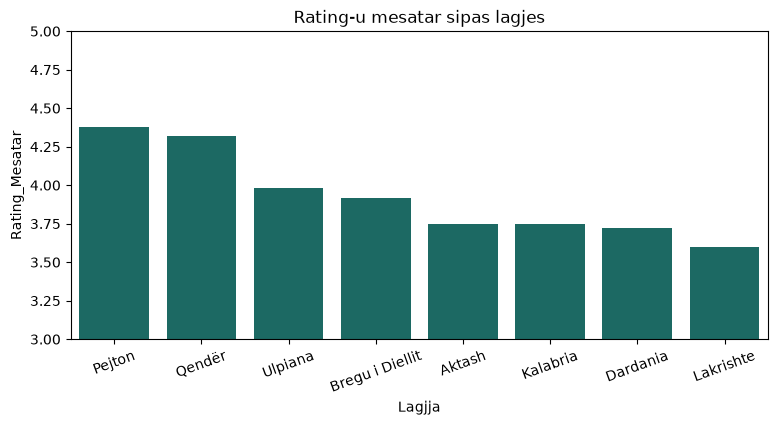

In [14]:
plt.figure(figsize=(9, 4))
sns.barplot(data=rating_lagje.reset_index(), x='Lagjja', y='Rating_Mesatar', color='#0F766E')
plt.title('Rating-u mesatar sipas lagjes')
plt.ylim(3, 5)
plt.xticks(rotation=20)
plt.show()

### Pyetja 2: Si ndryshojnë çmimet sipas tipit?

In [15]:
df.groupby('Tipi')['Cmimi_Mesatar'].agg(['mean', 'median', 'min', 'max']).round(2)

,mean,median,min,max
Tipi,,,,
Bar,6.00,6.0,4.0,8.5
Kafe,2.57,2.6,1.5,3.5
Pizzeri,5.08,5.0,4.0,6.5
Restorant,14.25,13.5,7.5,25.0


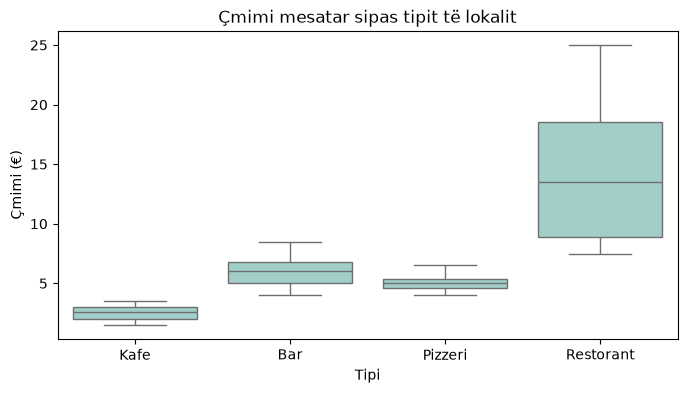

In [16]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='Tipi', y='Cmimi_Mesatar', color='#99D5CF')
plt.title('Çmimi mesatar sipas tipit të lokalit')
plt.ylabel('Çmimi (€)')
plt.show()

### Pyetja 3: Top 5 lokalet me "vlerë për para" më të mirë

In [17]:
df.nlargest(5, 'Value_Score')[['Emri', 'Lagjja', 'Tipi', 'Cmimi_Mesatar', 'Rating', 'Value_Score']]

,Emri,Lagjja,Tipi,Cmimi_Mesatar,Rating,Value_Score
10,Te Blerimi,Lakrishte,Kafe,1.5,3.5,2.33
8,Kafe Mëngjesi,Bregu i Diellit,Kafe,2.0,4.0,2.00
38,Te Shpati,Dardania,Kafe,1.8,3.4,1.89
11,Kafe Filxhani,Kalabria,Kafe,2.0,3.7,1.85
41,Kafe Bora,Bregu i Diellit,Kafe,2.0,3.7,1.85


### Pyetja 4: A lidhet çmimi me rating-un?

Korrelacioni Çmim–Rating: 0.48


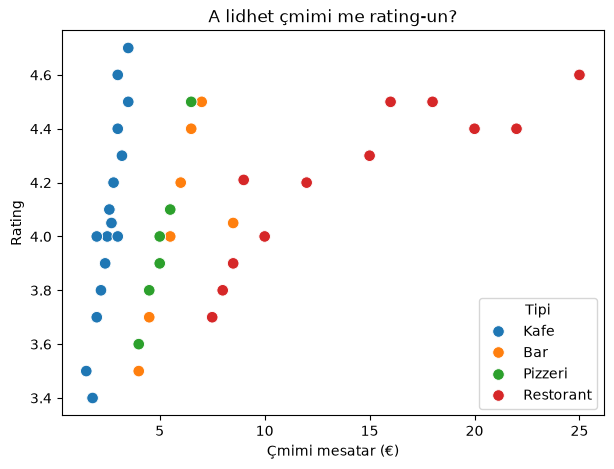

In [18]:
korrelacioni = df['Cmimi_Mesatar'].corr(df['Rating'])
print(f'Korrelacioni Çmim–Rating: {korrelacioni:.2f}')

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='Cmimi_Mesatar', y='Rating', hue='Tipi', s=70)
plt.title('A lidhet çmimi me rating-un?')
plt.xlabel('Çmimi mesatar (€)')
plt.show()

In [19]:
# Korrelacioni brenda secilit tip lokali
df.groupby('Tipi')[['Cmimi_Mesatar', 'Rating']].corr().xs('Rating', level=1)['Cmimi_Mesatar'].round(2)

Tipi
Bar          0.69
Kafe         0.91
Pizzeri      0.99
Restorant    0.88
Name: Cmimi_Mesatar, dtype: float64

**Interpretim:** Në total korrelacioni është mesatar (~0.5). Por **brenda secilit tip** (Kafe, Bar, Pizzeri, Restorant) lidhja është shumë e fortë (> 0.9): lokalet më të shtrenjta të të njëjtit tip kanë rating më të lartë.

Pse ndryshon kaq shumë? Sepse tipet kanë nivele çmimesh shumë të ndryshme — një kafe e mirë kushton më pak se një restorant mesatar. Kur i përziejmë, lidhja "fshihet". **Mësimi:** gjithmonë kontrollo lidhjet edhe brenda grupeve, jo vetëm në total.

---
# Practice Time 

## Ushtrimi 1 — Lokali Premium

Gjeni të gjitha **restorantet** që:
- Janë në lagjet **Qendër** ose **Pejton**
- Kanë **Rating ≥ 4.0**
- Kanë **çmim mesatar mbi 15 €**

Renditini sipas Rating-ut (më të lartin së pari) dhe shfaqni vetëm kolonat: 
`Emri`, `Lagjja`, `Cmimi_Mesatar`, `Rating`, `Nr_Komente`.

##  Ushtrimi 2 — Raport për Investitor (me grafik)

Imagjinoni se një investitor po ju pyet: **"Në cilën lagje të Prishtinës dhe me çfarë tipi lokali të investoj?"**

1. Bëni një **groupby** sipas `Lagjja` dhe `Tipi`, llogaritni:
   - Numrin e lokaleve
   - Rating-un mesatar
   - Çmimin mesatar (€)
2. Filtroni vetëm kombinimet që kanë **të paktën 2 lokale** (që të jenë reprezentative).
3. Krijoni një **bar chart** që tregon Rating mesatar për 5 kombinimet TOP.
